# Your embedding upgrade is a migration, not a config change
### A small, runnable experiment

This notebook reproduces the article's claims on a real (small) IR benchmark, on
a laptop, for **free** — local models, no API key, no cost. It runs four tests:

1. **The silent failure** — swap only the *query* model, leave documents in the old
   space, and recall collapses with **no error**.
2. **Worst at the start** — re-embed 0 → 100% of the corpus and watch recall recover.
3. **Space-compatibility probe** — measure whether two models share a space *before*
   you commit to a re-embed.
4. **The drift adapter** *(the interesting one)* — learn a linear map from the old
   space to the new one and measure **how much of the lost recall it recovers.** This
   number is genuinely unknown in advance — report whatever you get.

> This is a **scaled-down reproduction** with small local models, not the real
> OpenAI production case. Describe it honestly as exactly that. Run every cell in
> order (Shift+Enter).

In [10]:
# One-time install. If it's already installed this is instant.
%pip install -q "sentence-transformers" "datasets" numpy matplotlib

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [11]:
%matplotlib inline
from collections import defaultdict
import numpy as np
from datasets import load_dataset
from sentence_transformers import SentenceTransformer

# Two DIFFERENT models with the SAME output dimension (384). Same dimension is the
# whole point: the cross-space comparison runs with NO error. Different dimensions
# would crash loudly instead of failing silently.
OLD_MODEL = "sentence-transformers/all-MiniLM-L6-v2"          # the "old" model
NEW_MODEL = "sentence-transformers/paraphrase-MiniLM-L6-v2"   # the "new" model
K = 10                      # recall@K
DATASET = "BeIR/scifact"    # small scientific-claims benchmark (~5k docs)
SEED = 0

In [12]:
# Load a small real IR benchmark.
print(f"Loading {DATASET} ...")
corpus  = load_dataset(DATASET, "corpus")["corpus"]
queries = load_dataset(DATASET, "queries")["queries"]
qrels   = load_dataset(DATASET + "-qrels")["test"]

doc_text   = {d["_id"]: (d.get("title", "") + " " + d["text"]).strip() for d in corpus}
query_text = {q["_id"]: q["text"] for q in queries}

relevant = defaultdict(set)                       # query_id -> {relevant doc_ids}
for r in qrels:
    if r["score"] > 0:
        relevant[str(r["query-id"])].add(str(r["corpus-id"]))

doc_ids   = list(doc_text.keys())
doc_index = {d: i for i, d in enumerate(doc_ids)}
q_ids = [q for q in relevant
         if q in query_text and any(d in doc_index for d in relevant[q])]
docs   = [doc_text[d] for d in doc_ids]
qtexts = [query_text[q] for q in q_ids]
print(f"{len(doc_ids)} documents, {len(q_ids)} evaluation queries.")

Loading BeIR/scifact ...
5183 documents, 300 evaluation queries.


In [13]:
# Embed the corpus in BOTH spaces, and the queries in the NEW space.
# This is the slow cell (downloads two small models the first time). ~5-10 min on CPU.
def embed(model_name, texts):
    print(f"  embedding {len(texts)} texts with {model_name} ...")
    m = SentenceTransformer(model_name)
    return np.asarray(
        m.encode(texts, batch_size=64, show_progress_bar=True,
                 normalize_embeddings=True), dtype=np.float32)

def normalize(v):
    n = np.linalg.norm(v, axis=1, keepdims=True); n[n == 0] = 1.0
    return v / n

docs_old = embed(OLD_MODEL, docs)
docs_new = embed(NEW_MODEL, docs)
q_new    = embed(NEW_MODEL, qtexts)   # queries live in the NEW space in every test
print("done.")

  embedding 5183 texts with sentence-transformers/all-MiniLM-L6-v2 ...


Batches: 100%|██████████| 81/81 [00:23<00:00,  3.42it/s]


  embedding 5183 texts with sentence-transformers/paraphrase-MiniLM-L6-v2 ...


Batches: 100%|██████████| 81/81 [00:09<00:00,  8.61it/s]


  embedding 300 texts with sentence-transformers/paraphrase-MiniLM-L6-v2 ...


Batches: 100%|██████████| 5/5 [00:00<00:00, 22.43it/s]

done.


In [14]:
# recall@K helper (cosine == dot product because vectors are normalized)
def recall_at_k(query_vecs, doc_vecs, k=K):
    sims = query_vecs @ doc_vecs.T
    topk = np.argpartition(-sims, k, axis=1)[:, :k]
    hits = total = 0
    for i, qid in enumerate(q_ids):
        rel = relevant[qid]
        retrieved = {doc_ids[j] for j in topk[i]}
        hits  += len(retrieved & rel)
        total += len(rel)
    return hits / total

## Test 1 — Swapping only the query model fails silently
`baseline` = everything already in the new space (the goal).
`crossed` = new-model queries scored against old-model documents (the broken, mid-migration state). Nothing errors — recall just drops.

In [15]:
baseline = recall_at_k(q_new, docs_new)   # target: fully migrated
crossed  = recall_at_k(q_new, docs_old)   # NEW queries vs OLD docs (no error!)
print(f"recall@{K}  NEW queries vs NEW docs : {baseline:.3f}   (target, fully migrated)")
print(f"recall@{K}  NEW queries vs OLD docs : {crossed:.3f}   (nothing errored)")
if baseline:
    print(f"=> relative drop while half-migrated: {100*(baseline-crossed)/baseline:.0f}%")

recall@10  NEW queries vs NEW docs : 0.646   (target, fully migrated)
recall@10  NEW queries vs OLD docs : 0.590   (nothing errored)
=> relative drop while half-migrated: 9%


## Test 2 — Worst at the START of the migration, not the middle
Re-embed a random fraction `f` of the documents into the new space, keep queries in the new space, and measure recall at each step. If the article is right, the curve is lowest at `f = 0` and climbs from there.

fraction re-embedded 0.0  ->  recall@10 = 0.590
fraction re-embedded 0.1  ->  recall@10 = 0.366
fraction re-embedded 0.2  ->  recall@10 = 0.316
fraction re-embedded 0.3  ->  recall@10 = 0.348
fraction re-embedded 0.4  ->  recall@10 = 0.366
fraction re-embedded 0.5  ->  recall@10 = 0.410
fraction re-embedded 0.6  ->  recall@10 = 0.463
fraction re-embedded 0.7  ->  recall@10 = 0.513
fraction re-embedded 0.8  ->  recall@10 = 0.558
fraction re-embedded 0.9  ->  recall@10 = 0.596
fraction re-embedded 1.0  ->  recall@10 = 0.646


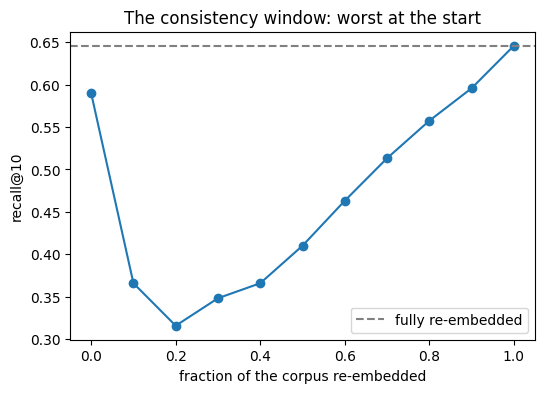

In [16]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(doc_ids))
fractions = np.linspace(0, 1, 11)
curve = []
for f in fractions:
    n = int(f * len(doc_ids))
    mixed = docs_old.copy()
    mixed[order[:n]] = docs_new[order[:n]]   # these docs are "re-embedded"
    curve.append(recall_at_k(q_new, mixed))
    print(f"fraction re-embedded {f:0.1f}  ->  recall@{K} = {curve[-1]:.3f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
plt.plot(fractions, curve, marker="o")
plt.axhline(curve[-1], ls="--", color="gray", label="fully re-embedded")
plt.xlabel("fraction of the corpus re-embedded"); plt.ylabel(f"recall@{K}")
plt.title("The consistency window: worst at the start"); plt.legend(); plt.show()

## Test 3 — Do the two models share a space?
A cheap pre-check: how often do a document's nearest neighbours in the old space stay its neighbours in the new space? ~1.0 means the spaces are basically the same; near 0 means they are unrelated.

In [17]:
def neighbours(vecs, k=10):
    s = vecs @ vecs.T; np.fill_diagonal(s, -1)
    return np.argpartition(-s, k, axis=1)[:, :k]
nn_old, nn_new = neighbours(docs_old), neighbours(docs_new)
overlap = np.mean([len(set(a) & set(b))/10 for a, b in zip(nn_old, nn_new)])
print(f"avg nearest-neighbour overlap between the two spaces: {overlap:.2f}")
print("(1.0 = identical neighbourhoods, ~0 = unrelated spaces)")

avg nearest-neighbour overlap between the two spaces: 0.43
(1.0 = identical neighbourhoods, ~0 = unrelated spaces)


## Test 4 — Does a drift adapter actually recover the lost recall?
**This is the one worth writing about.** We learn a linear map `W` from the old space
to the new space on *half* the documents, apply it to the rest, and see how much of the
recall gap it closes. The result is genuinely unknown in advance — it could recover most
of the loss, or almost none. Report whatever you get, even if it surprises you.

recall@10  floor   (broken, no fix)         : 0.590
recall@10  adapter (mapped-old docs)        : 0.673
recall@10  target  (fully re-embedded)      : 0.646
=> the drift adapter recovered 147% of the lost recall
   (held-out linear-map residual: 0.62; lower = closer to a linear transform)


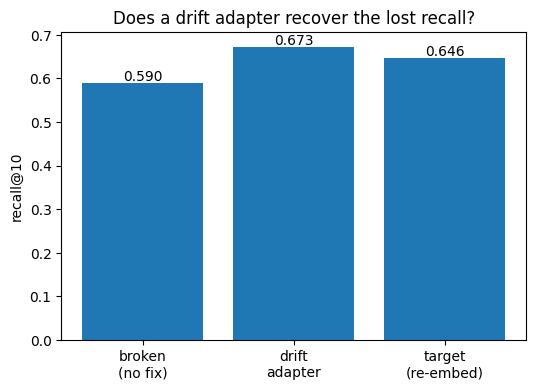

In [18]:
half = len(doc_ids) // 2
train = order[:half]                       # docs we "have in both spaces"
W, *_ = np.linalg.lstsq(docs_old[train], docs_new[train], rcond=None)
adapted = normalize(docs_old @ W)          # map every old vector into ~new space
recovered = recall_at_k(q_new, adapted)

span = baseline - crossed
frac = (recovered - crossed) / span if span > 0 else float("nan")
resid = (np.linalg.norm(docs_old[order[half:]] @ W - docs_new[order[half:]])
         / np.linalg.norm(docs_new[order[half:]]))
print(f"recall@{K}  floor   (broken, no fix)         : {crossed:.3f}")
print(f"recall@{K}  adapter (mapped-old docs)        : {recovered:.3f}")
print(f"recall@{K}  target  (fully re-embedded)      : {baseline:.3f}")
print(f"=> the drift adapter recovered {100*frac:.0f}% of the lost recall")
print(f"   (held-out linear-map residual: {resid:.2f}; lower = closer to a linear transform)")

plt.figure(figsize=(6,4))
labels = ["broken\n(no fix)", "drift\nadapter", "target\n(re-embed)"]
vals = [crossed, recovered, baseline]
plt.bar(labels, vals)
for i, v in enumerate(vals): plt.text(i, v+0.005, f"{v:.3f}", ha="center")
plt.ylabel(f"recall@{K}"); plt.title("Does a drift adapter recover the lost recall?"); plt.show()

## Test 5 — Why does the valley happen? A score-scale mismatch

In a half-migrated index, a new-model query is compared to *some* old-space documents and *some* new-space documents at once. If the two spaces put their cosine scores on different scales, one group is systematically scored higher and crowds the top-K — which would explain why a mixed index is worse than either pure one. This cell measures that gap directly.

In [19]:
# TEST 5: WHY the valley? Compare the score SCALES of the two spaces.
S_new = q_new @ docs_new.T   # new query vs new-space docs
S_old = q_new @ docs_old.T   # new query vs old-space docs
print(f"new-query vs NEW-space docs : mean cos {S_new.mean():.3f}, std {S_new.std():.3f}")
print(f"new-query vs OLD-space docs : mean cos {S_old.mean():.3f}, std {S_old.std():.3f}")
print(f"=> gap between the two score scales (old - new): {S_old.mean()-S_new.mean():+.3f}")
print()
print("If the two means differ, then in a MIXED index one space's docs are")
print("systematically scored higher and crowd out the other in the top-K.")
print("That score-scale mismatch is what produces the valley.")

new-query vs NEW-space docs : mean cos 0.146, std 0.120
new-query vs OLD-space docs : mean cos 0.081, std 0.088
=> gap between the two score scales (old - new): -0.065

If the two means differ, then in a MIXED index one space's docs are
systematically scored higher and crowd out the other in the top-K.
That score-scale mismatch is what produces the valley.


## Test 6 — Does per-space score normalization fix the valley?

If the valley is a score-scale problem, then standardizing scores *within each space* before merging them should flatten it. This reruns the migration curve two ways — raw, and with per-space normalization — and compares.

f=0.0   raw=0.590   per-space-normalized=0.590
f=0.1   raw=0.366   per-space-normalized=0.605
f=0.2   raw=0.316   per-space-normalized=0.587
f=0.3   raw=0.348   per-space-normalized=0.596
f=0.4   raw=0.366   per-space-normalized=0.608
f=0.5   raw=0.410   per-space-normalized=0.605
f=0.6   raw=0.463   per-space-normalized=0.622
f=0.7   raw=0.513   per-space-normalized=0.646
f=0.8   raw=0.558   per-space-normalized=0.652
f=0.9   raw=0.596   per-space-normalized=0.634
f=1.0   raw=0.646   per-space-normalized=0.646

raw trough        : 0.316 at f=0.2
normalized trough : 0.587 at f=0.2
If the normalized line stays flat while raw dips, per-space normalization fixes it.


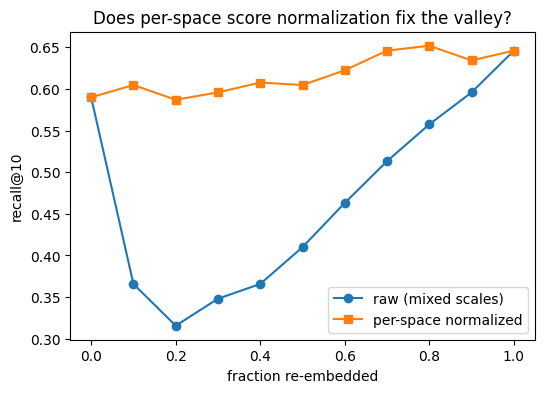

In [20]:
# TEST 6: does standardizing scores WITHIN each space flatten the valley?
def recall_from_scores(S, k=K):
    topk = np.argpartition(-S, k, axis=1)[:, :k]
    hits = total = 0
    for i, qid in enumerate(q_ids):
        rel = relevant[qid]
        retrieved = {doc_ids[j] for j in topk[i]}
        hits += len(retrieved & rel); total += len(rel)
    return hits / total

def mixed_scores(f, order, standardize):
    N = len(doc_ids); n = int(f * N)
    is_new = np.zeros(N, bool); is_new[order[:n]] = True
    S = np.empty((len(q_ids), N), dtype=np.float32)
    if is_new.any():    S[:, is_new]  = q_new @ docs_new[is_new].T
    if (~is_new).any(): S[:, ~is_new] = q_new @ docs_old[~is_new].T
    if standardize:                       # z-score each space separately, per query
        for mask in (is_new, ~is_new):
            if mask.sum() > 1:
                sub = S[:, mask]
                mu = sub.mean(1, keepdims=True); sd = sub.std(1, keepdims=True) + 1e-8
                S[:, mask] = (sub - mu) / sd
    return S

order = np.random.default_rng(SEED).permutation(len(doc_ids))
raw  = [recall_from_scores(mixed_scores(f, order, False)) for f in fractions]
norm = [recall_from_scores(mixed_scores(f, order, True))  for f in fractions]
for f, a, b in zip(fractions, raw, norm):
    print(f"f={f:0.1f}   raw={a:.3f}   per-space-normalized={b:.3f}")
print(f"\nraw trough        : {min(raw):.3f} at f={fractions[int(np.argmin(raw))]:.1f}")
print(f"normalized trough : {min(norm):.3f} at f={fractions[int(np.argmin(norm))]:.1f}")
print("If the normalized line stays flat while raw dips, per-space normalization fixes it.")

plt.figure(figsize=(6,4))
plt.plot(fractions, raw,  marker='o', label='raw (mixed scales)')
plt.plot(fractions, norm, marker='s', label='per-space normalized')
plt.xlabel('fraction re-embedded'); plt.ylabel(f'recall@{K}')
plt.title('Does per-space score normalization fix the valley?'); plt.legend(); plt.show()

## Test 7 — Is the valley robust across random orderings?

The curve in Test 2 used one random migration order. This reruns it for five different seeds. If every seed dips below both endpoints, the valley is a real effect, not a fluke of one shuffle.

seed 0: trough 0.316 at f=0.2   (endpoints 0.590 / 0.646)
seed 1: trough 0.316 at f=0.1   (endpoints 0.590 / 0.646)
seed 2: trough 0.336 at f=0.2   (endpoints 0.590 / 0.646)
seed 3: trough 0.369 at f=0.2   (endpoints 0.590 / 0.646)
seed 4: trough 0.307 at f=0.3   (endpoints 0.590 / 0.646)

across 5 seeds: mean trough 0.329, mean endpoints 0.590 / 0.646
If every seed's trough sits below BOTH endpoints, the valley is a real effect.


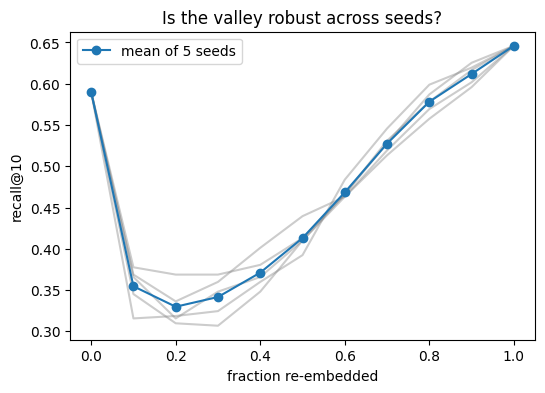

In [21]:
# TEST 7: is the valley real, or a fluke of one random ordering? Try 5 seeds.
# (uses recall_from_scores + mixed_scores from Test 6 -- run that cell first)
allcurves = []
for s in range(5):
    o = np.random.default_rng(s).permutation(len(doc_ids))
    c = [recall_from_scores(mixed_scores(f, o, False)) for f in fractions]
    allcurves.append(c)
    ti = int(np.argmin(c))
    print(f"seed {s}: trough {min(c):.3f} at f={fractions[ti]:.1f}   "
          f"(endpoints {c[0]:.3f} / {c[-1]:.3f})")
allcurves = np.array(allcurves)
mean_c = allcurves.mean(0)
print(f"\nacross 5 seeds: mean trough {allcurves.min(1).mean():.3f}, "
      f"mean endpoints {mean_c[0]:.3f} / {mean_c[-1]:.3f}")
print("If every seed's trough sits below BOTH endpoints, the valley is a real effect.")

plt.figure(figsize=(6,4))
for c in allcurves:
    plt.plot(fractions, c, color='gray', alpha=0.4)
plt.plot(fractions, mean_c, marker='o', color='C0', label='mean of 5 seeds')
plt.xlabel('fraction re-embedded'); plt.ylabel(f'recall@{K}')
plt.title('Is the valley robust across seeds?'); plt.legend(); plt.show()

## Now write down what actually happened

In your own words, and honestly:

- **How big was the silent drop** (Test 1)?
- **Was the curve really worst at the very start** (Test 2)?
- **How much did the drift adapter recover** (Test 4)? That number is the one nobody
  could have told you in advance — it is the closest thing here to a finding of your own.

If a result surprises you or cuts against the article, that is the *good* case — say so,
and adjust the article to match what you actually measured.